# Simple Chatbot Graph with LangGraph
A minimal chatbot implementation with Start -> Chat_Node -> End flow

## 1. Dependencies

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.messages import BaseMessage, HumanMessage

print("✓ Dependencies imported successfully")

✓ Dependencies imported successfully


## 2. Load Environment Variables

In [2]:
# Load environment variables from parent directory
ENV_PATH = Path("/home/program/Documents/Tutor/Campus/5_LangSmith/.env")
load_dotenv(ENV_PATH)

api_key = os.getenv("OPENROUTER_API_KEY")

if api_key:
    print(f"✓ API Key loaded: {api_key[:20]}...")
else:
    print("✗ API Key not found")

✓ API Key loaded: sk-or-v1-1e5e18b3f56...


## 3. Initialize LLM

In [3]:
# Initialize the LLM with OpenRouter
llm = ChatOpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=api_key,
    model="nvidia/nemotron-3.5-lightning:free",
)

print("✓ LLM initialized with OpenRouter")
print(f"  Model: nvidia/nemotron-3.5-lightning:free")

✓ LLM initialized with OpenRouter
  Model: nvidia/nemotron-3.5-lightning:free


## 4. Define Chat State

In [4]:
# Define the state structure for the chatbot
class ChatState(TypedDict):
    """State structure for the chat graph"""
    message: Annotated[list[BaseMessage], add_messages]

print("✓ ChatState defined")

✓ ChatState defined


## 5. Define Chat Node

In [5]:
def ChatNode(state: ChatState):
    """
    Chat node that processes user messages and returns LLM response.
    
    Args:
        state: ChatState containing list of messages
    
    Returns:
        dict with updated message list including LLM response
    """
    user_message = state['message']
    llm_response = llm.invoke(user_message)
    return {'message': [llm_response]}

print("✓ ChatNode function defined")

✓ ChatNode function defined


## 6. Build the Graph

In [6]:
# Create the state graph
graph = StateGraph(ChatState)

# Add nodes
graph.add_node('ChatNode', ChatNode)

# Add edges: START -> ChatNode -> END
graph.add_edge(START, 'ChatNode')
graph.add_edge('ChatNode', END)

print("✓ Graph structure created: START -> ChatNode -> END")

✓ Graph structure created: START -> ChatNode -> END


## 7. Compile the Graph with Memory Checkpointer

In [7]:
# Create a memory checkpointer for conversation history
checkpointer = InMemorySaver()

# Compile the graph
chatbot = graph.compile(checkpointer=checkpointer)

print("✓ Graph compiled with InMemorySaver checkpointer")

✓ Graph compiled with InMemorySaver checkpointer


## 8. Test the Chatbot

In [ ]:
# Test the chatbot
test_message = "Hello! What is LangGraph?"
thread_id = "test-thread-1"

config = {
    'configurable': {
        'thread_id': thread_id
    }
}

print(f"\n📝 User Message: {test_message}")
print("\n⏳ Waiting for response...\n")

# Stream the response
response = chatbot.invoke({'message':[HumanMessage(content=test_message)]},config = config)
print(f"Assistant response: {response['message'][-1].content}")


📝 User Message: Hello! What is LangGraph?

⏳ Waiting for response...

Assistant response: **LangGraph** is a Python library (part of the LangChain ecosystem) for building **stateful, multi-agent, and cyclic LLM applications**. 

While standard LangChain chains are strictly linear (Step A → Step B → Step C), LangGraph models execution as a **directed graph**, where:
- **Nodes** are operations (LLM calls, tool usage, logic, filtering)
- **Edges** define transitions—including branches, loops, and cycles
- A **shared state object** persists across steps, enabling memory, context, and incremental updates

### Why use it instead of linear chains?
| Situation | Better Fit |
|-----------|------------|
| One-shot prompt → response | LangChain `LCEL` / simple chains |
| Autonomous agent that plans → uses tools → reflects → retries | **LangGraph** (cycles/loops) |
| Needs memory of prior turns or checkpoints | LangGraph (built-in checkpointing) |
| Routing based on conditions (e.g., "if tool nee

## 9. Graph Visualization

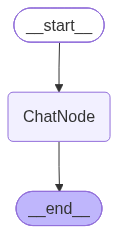

✓ Graph visualization displayed


In [10]:
# Visualize the graph structure
try:
    from IPython.display import Image, display
    # Generate graph image
    graph_image = chatbot.get_graph().draw_mermaid_png()
    display(Image(graph_image))
    print("✓ Graph visualization displayed")
except Exception as e:
    print(f"Note: Visualization requires graphviz. Error: {e}")
    print("\nGraph Structure:")
    print("  START")
    print("    ↓")
    print("  ChatNode (processes messages with LLM)")
    print("    ↓")
    print("  END")